In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Dimensions des données :")
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensions des données :
(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [3]:
# Transformation des images en vecteurs
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

# Mettre les valeurs des vecteur dans un intervalle entre 0 et 1
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Nouvelle dimension :", X_train.shape)

Nouvelle dimension : (60000, 784)


In [4]:
# Dimensions du réseau
taille_entree = 784
taille_couche_cache = 32
taille_sortie = 10

# Les fonction d'activation
ReLU renvoie 0 si la valeur est négative sinon la valeur initial

SoftMax permet de transformer les sortie de la couche de sortie en probabilité

In [5]:
def relu(x):
    return np.maximum(0, x)

def softmax(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)

    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


In [6]:
def propagation(X):
    # Couche cachée
    somme_couche_cachee = X @ poids_couche_cachee + biais_couche_cachee
    activation_couche_cachee = relu(somme_couche_cachee)

    # Couche de sortie
    somme_couche_sortie = activation_couche_cachee @ poids_couche_sortie + biais_couche_sortie
    activation_couche_sortie = softmax(somme_couche_sortie)

    return somme_couche_cachee, activation_couche_cachee, somme_couche_sortie, activation_couche_sortie

# Les fonction de couts

On souhaite tester l'entrainement du réseau par rapport à deux fonction de couts MSE et l'entropie

Ce qui nécessite donc leur fonction de rétropropagation associé

In [7]:
# === Version 1 : SOFTMAX + ENTROPIE CROISÉE ===

def fonction_couts_entropie(predictions, chiffres_reels):
    m = chiffres_reels.shape[0]
    epsilon = 1e-12
    predictions_correctes = predictions[np.arange(m), chiffres_reels]
    perte = -np.mean(np.log(predictions_correctes + epsilon))
    return perte

def retropropagation_entropie(X, chiffres_reels, somme_couche_cachee, activation_couche_cachee, activation_couche_sortie):
    m = X.shape[0]

    # Gradient par rapport à la somme de sortie
    gradient_somme_sortie = activation_couche_sortie.copy()
    gradient_somme_sortie[np.arange(m), chiffres_reels] -= 1
    gradient_somme_sortie /= m

    # Gradients par rapport aux parametres de la couche de sortie
    gradient_poids_sortie = activation_couche_cachee.T @ gradient_somme_sortie
    gradient_biais_sortie = np.sum(gradient_somme_sortie, axis=0, keepdims=True)

    # Propagation de l'erreur vers l'activation cachée
    gradient_activation_cachee = gradient_somme_sortie @ poids_couche_sortie.T

    # Gradient par rapport à la somme de la couche cachée (après ReLU)
    gradient_somme_cachee = gradient_activation_cachee * (somme_couche_cachee > 0)

    # Gradients par rapport aux parametres de la couche cachée
    gradient_poids_cachee = X.T @ gradient_somme_cachee
    gradient_biais_cachee = np.sum(gradient_somme_cachee, axis=0, keepdims=True)

    return gradient_poids_cachee, gradient_biais_cachee, gradient_poids_sortie, gradient_biais_sortie


# === Version2 : SOFTMAX + ERREUR QUADRATIQUE MOYENNE (MSE) ===

def fonction_couts_mse(predictions, chiffres_reels):
    m = chiffres_reels.shape[0]
    valeurs_attendues = np.zeros_like(predictions)
    valeurs_attendues[np.arange(m), chiffres_reels] = 1.0
    # Calcul du MSE
    perte = np.mean((predictions - valeurs_attendues) ** 2)
    return perte

def retropropagation_mse(X, chiffres_reels, somme_couche_cachee, activation_couche_cachee, activation_couche_sortie):
    m = X.shape[0]
    valeurs_attendues = np.zeros_like(activation_couche_sortie)
    valeurs_attendues[np.arange(m), chiffres_reels] = 1.0

    #Dérivée de la MSE par rapport aux activations de sortie
    gradient_activation_sortie = (2 / activation_couche_sortie.shape[1]) * (activation_couche_sortie -valeurs_attendues)

    # Dérivée de la Softmax par rapport à la somme de sortie
    gradient_somme_sortie = activation_couche_sortie * (gradient_activation_sortie - np.sum(gradient_activation_sortie * activation_couche_sortie, axis=1, keepdims=True))
    gradient_somme_sortie /= m

    #Gradients par rapport aux parametres de la couche de sortie
    gradient_poids_sortie = activation_couche_cachee.T @ gradient_somme_sortie
    gradient_biais_sortie = np.sum(gradient_somme_sortie, axis=0, keepdims=True)

    # Propagation de l'erreur vers la couche cachée
    gradient_activation_cachee = gradient_somme_sortie @ poids_couche_sortie.T

    # gradient par rapport à la somme de la couche cachée
    gradient_somme_cachee = gradient_activation_cachee * (somme_couche_cachee > 0)

    # Gradients par rapport aux parametres de la couche cachée
    gradient_poids_cachee = X.T @ gradient_somme_cachee
    gradient_biais_cachee = np.sum(gradient_somme_cachee, axis=0, keepdims=True)

    return gradient_poids_cachee, gradient_biais_cachee, gradient_poids_sortie, gradient_biais_sortie

In [8]:
def maj_parametres(gradient_poids_cachee, gradient_biais_cachee, gradient_poids_sortie, gradient_biais_sortie, taux_apprentisage):
    global poids_couche_cachee, biais_couche_cachee, poids_couche_sortie, biais_couche_sortie

    poids_couche_cachee -= taux_apprentisage * gradient_poids_cachee
    biais_couche_cachee -= taux_apprentisage * gradient_biais_cachee

    poids_couche_sortie -= taux_apprentisage * gradient_poids_sortie
    biais_couche_sortie -= taux_apprentisage * gradient_biais_sortie

# L'entrainement du réseau
La fonction prend en paramètres les images des chiffre, les chiffres associé, la fonction de couts/rétropropagation à utilisé, le nombre d'époque i.e combien de fois on fais passer les 60000 images, la taille des échantillon et enfin le taux d'apprentisage qui correspond à la taille des pas

In [9]:
def entrainement(X, y, fonction_perte_cible, retropropagation_cible, epoques=10, taille_echantillon=64, taux_apprentisage=0.1):
    n = X.shape[0]

    for epoque in range(epoques):
        # Mélange des données
        indices = np.random.permutation(n)
        X_melange = X[indices]
        y_melange = y[indices]

        perte_total = 0

        for i in range(0, n, taille_echantillon):
            X_echantillon = X_melange[i:i+taille_echantillon]
            y_echantillon = y_melange[i:i+taille_echantillon]

            # Propagation
            somme_couche_cachee, activation_couche_cachee, somme_couche_sortie, activation_couche_sortie = propagation(X_echantillon)

            # Calcul de l'erreur
            perte = fonction_perte_cible(activation_couche_sortie, y_echantillon)
            perte_total += perte * len(X_echantillon)

            # Rétropropagation
            gradients = retropropagation_cible(X_echantillon, y_echantillon, somme_couche_cachee, activation_couche_cachee, activation_couche_sortie)

            # Mise à jour des poids
            maj_parametres(*gradients, taux_apprentisage)

        # Évaluation de la précision
        _, _, _, toutes_predictions = propagation(X)
        classes_predites = np.argmax(toutes_predictions, axis=1)
        precision = np.mean(classes_predites == y) * 100

        print(f"Époque {epoque+1}/{epoques} - Loss : {perte_total/n:.6f} - Précision : {precision:.2f}%")

# Initialisation du réseau
On utilise des valeurs aléatoire selon la loi normal et on applique l'initialisation de He pour que les valeursdes poids ne diverge ou converge vers 0 (Même si dans notre cas cela reste peu probable due au nombre faible de couche)

In [10]:
# Fonction pour réinitialiser les poids
def reinitialiser_reseau():
    global poids_couche_cachee, biais_couche_cachee, poids_couche_sortie, biais_couche_sortie
    poids_couche_cachee = np.random.randn(taille_entree, taille_couche_cache) * np.sqrt(2 / taille_entree)
    biais_couche_cachee = np.zeros((1, taille_couche_cache))
    poids_couche_sortie = np.random.randn(taille_couche_cache, taille_sortie) * np.sqrt(2 / taille_couche_cache)
    biais_couche_sortie = np.zeros((1, taille_sortie))
    print("Réseau réinitialisé avec succès.")

# --- TEST 1 : Entraînement avec Entropie --
print("=== Entraînement: Softmax + Entropie===")
reinitialiser_reseau()
entrainement(X_train, y_train, fonction_couts_entropie, retropropagation_entropie, epoques=10, taux_apprentisage=0.1)


=== Entraînement: Softmax + Entropie===
Réseau réinitialisé avec succès.
Époque 1/10 - Loss : 0.396103 - Précision : 92.78%
Époque 2/10 - Loss : 0.234684 - Précision : 94.27%
Époque 3/10 - Loss : 0.188964 - Précision : 95.02%
Époque 4/10 - Loss : 0.161273 - Précision : 96.02%
Époque 5/10 - Loss : 0.141278 - Précision : 96.54%
Époque 6/10 - Loss : 0.127912 - Précision : 96.82%
Époque 7/10 - Loss : 0.116351 - Précision : 96.90%
Époque 8/10 - Loss : 0.107627 - Précision : 97.21%
Époque 9/10 - Loss : 0.100163 - Précision : 97.48%
Époque 10/10 - Loss : 0.094279 - Précision : 97.55%


In [14]:
# --- TEST 2 : Entraînement avec MSE ---
print("\n=== Entraînement : Softmax + MSE ===")
reinitialiser_reseau()
entrainement(X_train, y_train, fonction_couts_mse, retropropagation_mse, epoques=10, taux_apprentisage=0.1)


=== Entraînement : Softmax + MSE ===
Réseau réinitialisé avec succès.
Époque 1/10 - Loss : 0.065621 - Précision : 71.38%
Époque 2/10 - Loss : 0.031748 - Précision : 86.18%
Époque 3/10 - Loss : 0.021840 - Précision : 88.14%
Époque 4/10 - Loss : 0.018665 - Précision : 89.26%
Époque 5/10 - Loss : 0.016939 - Précision : 90.00%
Époque 6/10 - Loss : 0.015807 - Précision : 90.46%
Époque 7/10 - Loss : 0.014982 - Précision : 90.85%
Époque 8/10 - Loss : 0.014333 - Précision : 91.20%
Époque 9/10 - Loss : 0.013803 - Précision : 91.45%
Époque 10/10 - Loss : 0.013370 - Précision : 91.75%


# Gradient Checking
On calcule gradient analytique(avec la rétropropagation) et numérique(avec la formule de differentiation) en un point ou le gradient n'est pas nul i.e si l'on choisi un pixel dans le coin il à de grande chance d'être nul ou si on choisi une neurone ou la connexion est nul (du à ReLu)

In [15]:
def verifier_gradients(X, y, fonction_cout, retropropagation, epsilon=1e-5):
    # 1. Calculer les gradients analytiques
    somme_couche_cachee, activation_couche_cachee, somme_couche_sortie, activation_couche_sortie = propagation(X)
    gradient_poids_cachee, gradient_biais_cachee, gradient_poids_sortie, gradient_biais_sortie = retropropagation(X, y, somme_couche_cachee, activation_couche_cachee, activation_couche_sortie)

    # 2. Trouver un emplacement (pixel, neurone) où le gradient analytique est non nul
    indices_valides = np.where(np.abs(gradient_poids_cachee) > 1e-5)

    if len(indices_valides[0]) == 0:
        print("Aucun gradient non nul (> 1e-5) détecté sur cet échantillon.")
        return

    index_pixel = indices_valides[0][0]
    index_neurone = indices_valides[1][0]
    grad_analytique = gradient_poids_cachee[index_pixel, index_neurone]

    # 3. Calcul numérique du gradient
    poids_init = poids_couche_cachee[index_pixel, index_neurone]

    # Perturbation positive (+epsilon)
    poids_couche_cachee[index_pixel, index_neurone] = poids_init + epsilon
    _, _, _, activation_couche_sortie_plus = propagation(X)
    perte_plus = fonction_cout(activation_couche_sortie_plus, y)

    # Perturbation négative (-epsilon)
    poids_couche_cachee[index_pixel, index_neurone] = poids_init - epsilon
    _, _, _, activation_couche_sortie_moins = propagation(X)
    perte_moins = fonction_cout(activation_couche_sortie_moins, y)

    poids_couche_cachee[index_pixel, index_neurone] = poids_init

    # Calcul de la dérivée numérique
    grad_numerique = (perte_plus - perte_moins) / (2 * epsilon)

    # 4. Calcul de l'erreur
    denominateur = np.abs(grad_analytique) + np.abs(grad_numerique)
    erreur = np.abs(grad_analytique - grad_numerique) / denominateur if denominateur > 0 else 0.0

    print(f"Validation pour {fonction_cout.__name__} :")
    print(f" Coordonnées du poids testé: Pixel {index_pixel}, Neurone {index_neurone}")
    print(f"Gradient analytique: {grad_analytique:.10f}")
    print(f"Gradient numérique: {grad_numerique:.10f}")
    print(f"Erreur: {erreur:.10e}")
    if erreur < 1e-6:
        print("Les gradients correspondent\n")
    else:
        print("écart importantentre les gradients\n")

In [27]:
# Sélection d'un échantillon pour le test de validation
X_validation = X_train[:100]
y_validation = y_train[:100]

# 1. Validation pour l'Entropie Croisée
print("=== CONTRÔLE DU GRADIENT : ENTROPIE ===")
verifier_gradients(X_validation, y_validation, fonction_couts_entropie, retropropagation_entropie)

# 2. Validation pour leMSE
print("=== CONTRÔLE DU GRADIENT : MSE ===")
verifier_gradients(X_validation, y_validation, fonction_couts_mse, retropropagation_mse)

=== CONTRÔLE DU GRADIENT : ENTROPIE ===
Validation pour fonction_couts_entropie :
 Coordonnées du poids testé: Pixel 71, Neurone 1
Gradient analytique: -0.0000387703
Gradient numérique: -0.0000387703
Erreur: 5.8560637581e-08
Les gradients correspondent

=== CONTRÔLE DU GRADIENT : MSE ===
Validation pour fonction_couts_mse :
 Coordonnées du poids testé: Pixel 97, Neurone 0
Gradient analytique: -0.0001011985
Gradient numérique: -0.0001011985
Erreur: 2.5908866624e-10
Les gradients correspondent



## Test du Réseau sur une jeu de test nouveau

Précision du réseau : 96.78%


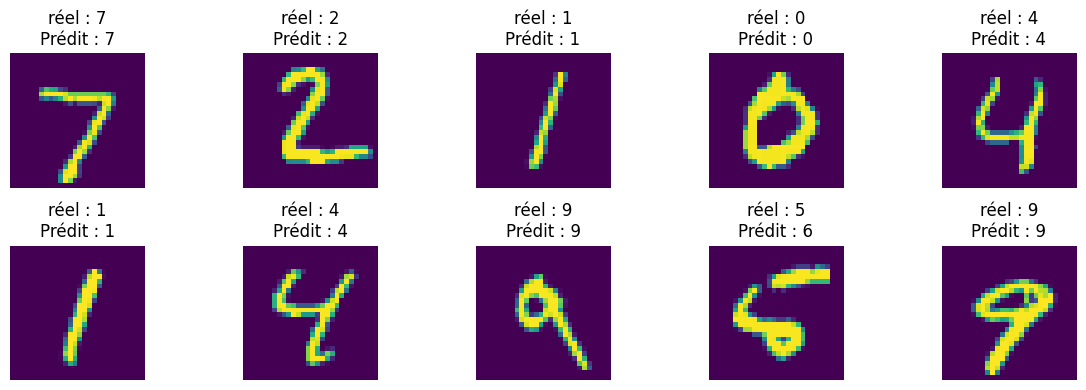

In [11]:
def evaluation(X, y):
    _, _, _, predictions = propagation(X)
    previsions = np.argmax(predictions, axis=1)
    precision = np.mean(previsions == y)
    print(f"Précision du réseau : {precision*100:.2f}%")
    return previsions

y_pred = evaluation(X_test, y_test)

def affichage_predictions(X, y, predictions, n=10):
    plt.figure(figsize=(12, 4))
    for i in range(n):
        plt.subplot(2, 5, i+1)
        plt.imshow(X[i].reshape(28, 28))
        plt.title(f"réel : {y[i]}\nPrédit : {predictions[i]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

affichage_predictions(X_test, y_test, y_pred)